# Analisi bayesiana — modello nominale (concordato con l'analisi frequentista)

Modello comune ai due metodi (deciso con Marco, 2026-10-06): finestra $[5100,5600]$ MeV, segnale gaussiano con $\mu,\sigma$ condivisi, fondo con rese indipendenti per carica ($N_b^\pm=N_b(1\mp A_b)/2$) e **doppio esponenziale con forma separata per carica**; likelihood estesa non binnata, prior uniformi. Il modello è in `bayesian_nominal.py`.

Il **modello semplificato** (6 parametri, finestra $[5150,5450]$, un esponenziale, fondo simmetrico) resta in `Bayesian_Analysis.ipynb` / `bayesian_model.py` con tutti i suoi risultati (`results/*.json`), invariato: i suoi 500 toy sono il closure test ad alta statistica della procedura.

Ordine: fit nominale → controlli (Bayes factor, catene disperse, polarità del magnete) → studio sistematico (varianti in parallelo) → toy-MC in parallelo → Dalitz → veti sul charm (solo informativi, stessa definizione dell'analisi frequentista) → salvataggio. Il risultato finale è il nominale senza veto. Ogni blocco lungo salva checkpoint riga per riga (`*.jsonl`) e riprende da dove si era fermato.

Modalità di test: `BAYES_NOMINAL_SMOKE=1` usa catene corte e pochi toy e scrive in `results/nominal_smoke/`.

In [1]:
import os, sys, json, time
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace, asdict

sys.path.insert(0, ".")
import bayesian_nominal as bn

SMOKE = os.environ.get("BAYES_NOMINAL_SMOKE", "0") == "1"
DATA_DIR = "../../opendata-project/Data"
RESULTS_DIR = os.path.join(os.getcwd(), "results", "nominal_smoke" if SMOKE else "nominal")
os.makedirs(RESULTS_DIR, exist_ok=True)

NSTEPS      = 1500 if SMOKE else 25000   # nominal and every variation (chain >= 50 tau for all parameters)
N_TOYS      = 4 if SMOKE else 200
NSTEPS_TOY  = 1500 if SMOKE else 12000   # tau ~ 150-185 at full length: >= 65 tau after burn-in
N_WORKERS   = max(1, (os.cpu_count() or 2) - 1)
N_THINNED   = 2000 if SMOKE else 20000   # posterior sample saved for the figures

def save_json(name, obj):
    path = os.path.join(RESULTS_DIR, name)
    with open(path, "w") as f:
        json.dump(obj, f, indent=1)
    print("[saved]", path)

print("SMOKE =", SMOKE, " RESULTS_DIR =", RESULTS_DIR, " workers =", N_WORKERS)

SMOKE = False  RESULTS_DIR = /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/nominal  workers = 9


In [2]:
cands = bn.load_candidates(DATA_DIR)
data_nom = bn.select(cands, bn.NOMINAL)
print(f"preselected candidates (|q|=1): {len(cands)};  in [{bn.NOMINAL.lo:.0f},{bn.NOMINAL.hi:.0f}] MeV: {len(data_nom)}")
print(f"  B+: {(data_nom.q > 0).sum()}   B-: {(data_nom.q < 0).sum()}   counting asymmetry: "
      f"{((data_nom.q < 0).sum() - (data_nom.q > 0).sum()) / len(data_nom):+.4f}")

preselected candidates (|q|=1): 37045;  in [5100,5600] MeV: 19731
  B+: 10292   B-: 9439   counting asymmetry: -0.0432


## Fit nominale

In [3]:
# resume: a completed nominal fit with the same configuration and chain length is loaded, not refitted
f_fit, f_th = os.path.join(RESULTS_DIR, "nominal_fit.json"), os.path.join(RESULTS_DIR, "nominal_posterior_thinned.npy")
prev = json.load(open(f_fit)) if os.path.exists(f_fit) and os.path.exists(f_th) else None
same_cfg = prev is not None and prev["config"] == json.loads(json.dumps(asdict(bn.NOMINAL)))  # tuples become lists in JSON
if same_cfg and prev["nsteps"] == NSTEPS:
    nominal = dict(prev, _thinned=np.load(f_th))
    print("[resume] nominal fit loaded from", f_fit)
else:
    nominal = bn.fit(data_nom.m, data_nom.q, bn.NOMINAL, nsteps=NSTEPS, keep_thinned=N_THINNED)
    np.save(f_th, nominal["_thinned"])
    save_json("nominal_fit.json", bn.to_jsonable(nominal))

A = nominal["A"]
print(f"A_raw = {A['median']:.4f}  68% CI [{A['ci68'][0]:.4f}, {A['ci68'][1]:.4f}]  95% CI [{A['ci95'][0]:.4f}, {A['ci95'][1]:.4f}]  sd {A['sd']:.4f}")
print(f"A_b   = {nominal['A_b']['median']:.4f} +- {nominal['A_b']['sd']:.4f}")
print(f"MAP A = {nominal['map']['A']:.4f}   (con prior piatti MAP = MLE: confronto diretto con il fit frequentista)")
print(f"chi2/ndof = {nominal['gof']['chi2']:.1f}/{nominal['gof']['ndof']}  p = {nominal['gof']['p']:.1e}")
print(f"acceptance {nominal['acceptance']:.2f};  chain/tau minimo = {nominal['chain_over_tau_min']:.0f} (deve essere > 50)")
for k, t in nominal["tau"].items():
    print(f"   tau[{k:9s}] = {t:6.1f}")
if not SMOKE:
    assert nominal["chain_over_tau_min"] > 50, "catena troppo corta rispetto a tau: aumentare NSTEPS"

[saved] /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/nominal/nominal_fit.json
A_raw = -0.0443  68% CI [-0.0528, -0.0358]  95% CI [-0.0608, -0.0276]  sd 0.0085
A_b   = -0.0400 +- 0.0176
MAP A = -0.0441   (con prior piatti MAP = MLE: confronto diretto con il fit frequentista)
chi2/ndof = 164.1/88  p = 1.6e-06
acceptance 0.38;  chain/tau minimo = 114 (deve essere > 50)
   tau[N_s      ] =  148.1
   tau[N_b      ] =  149.0
   tau[A        ] =  149.4
   tau[A_b      ] =  147.4
   tau[mu       ] =  177.3
   tau[sigma    ] =  162.8
   tau[lam1_pos ] =  183.3
   tau[lam2_pos ] =  167.8
   tau[f_pos    ] =  174.0
   tau[lam1_neg ] =  175.3
   tau[lam2_neg ] =  163.7
   tau[f_neg    ] =  171.8


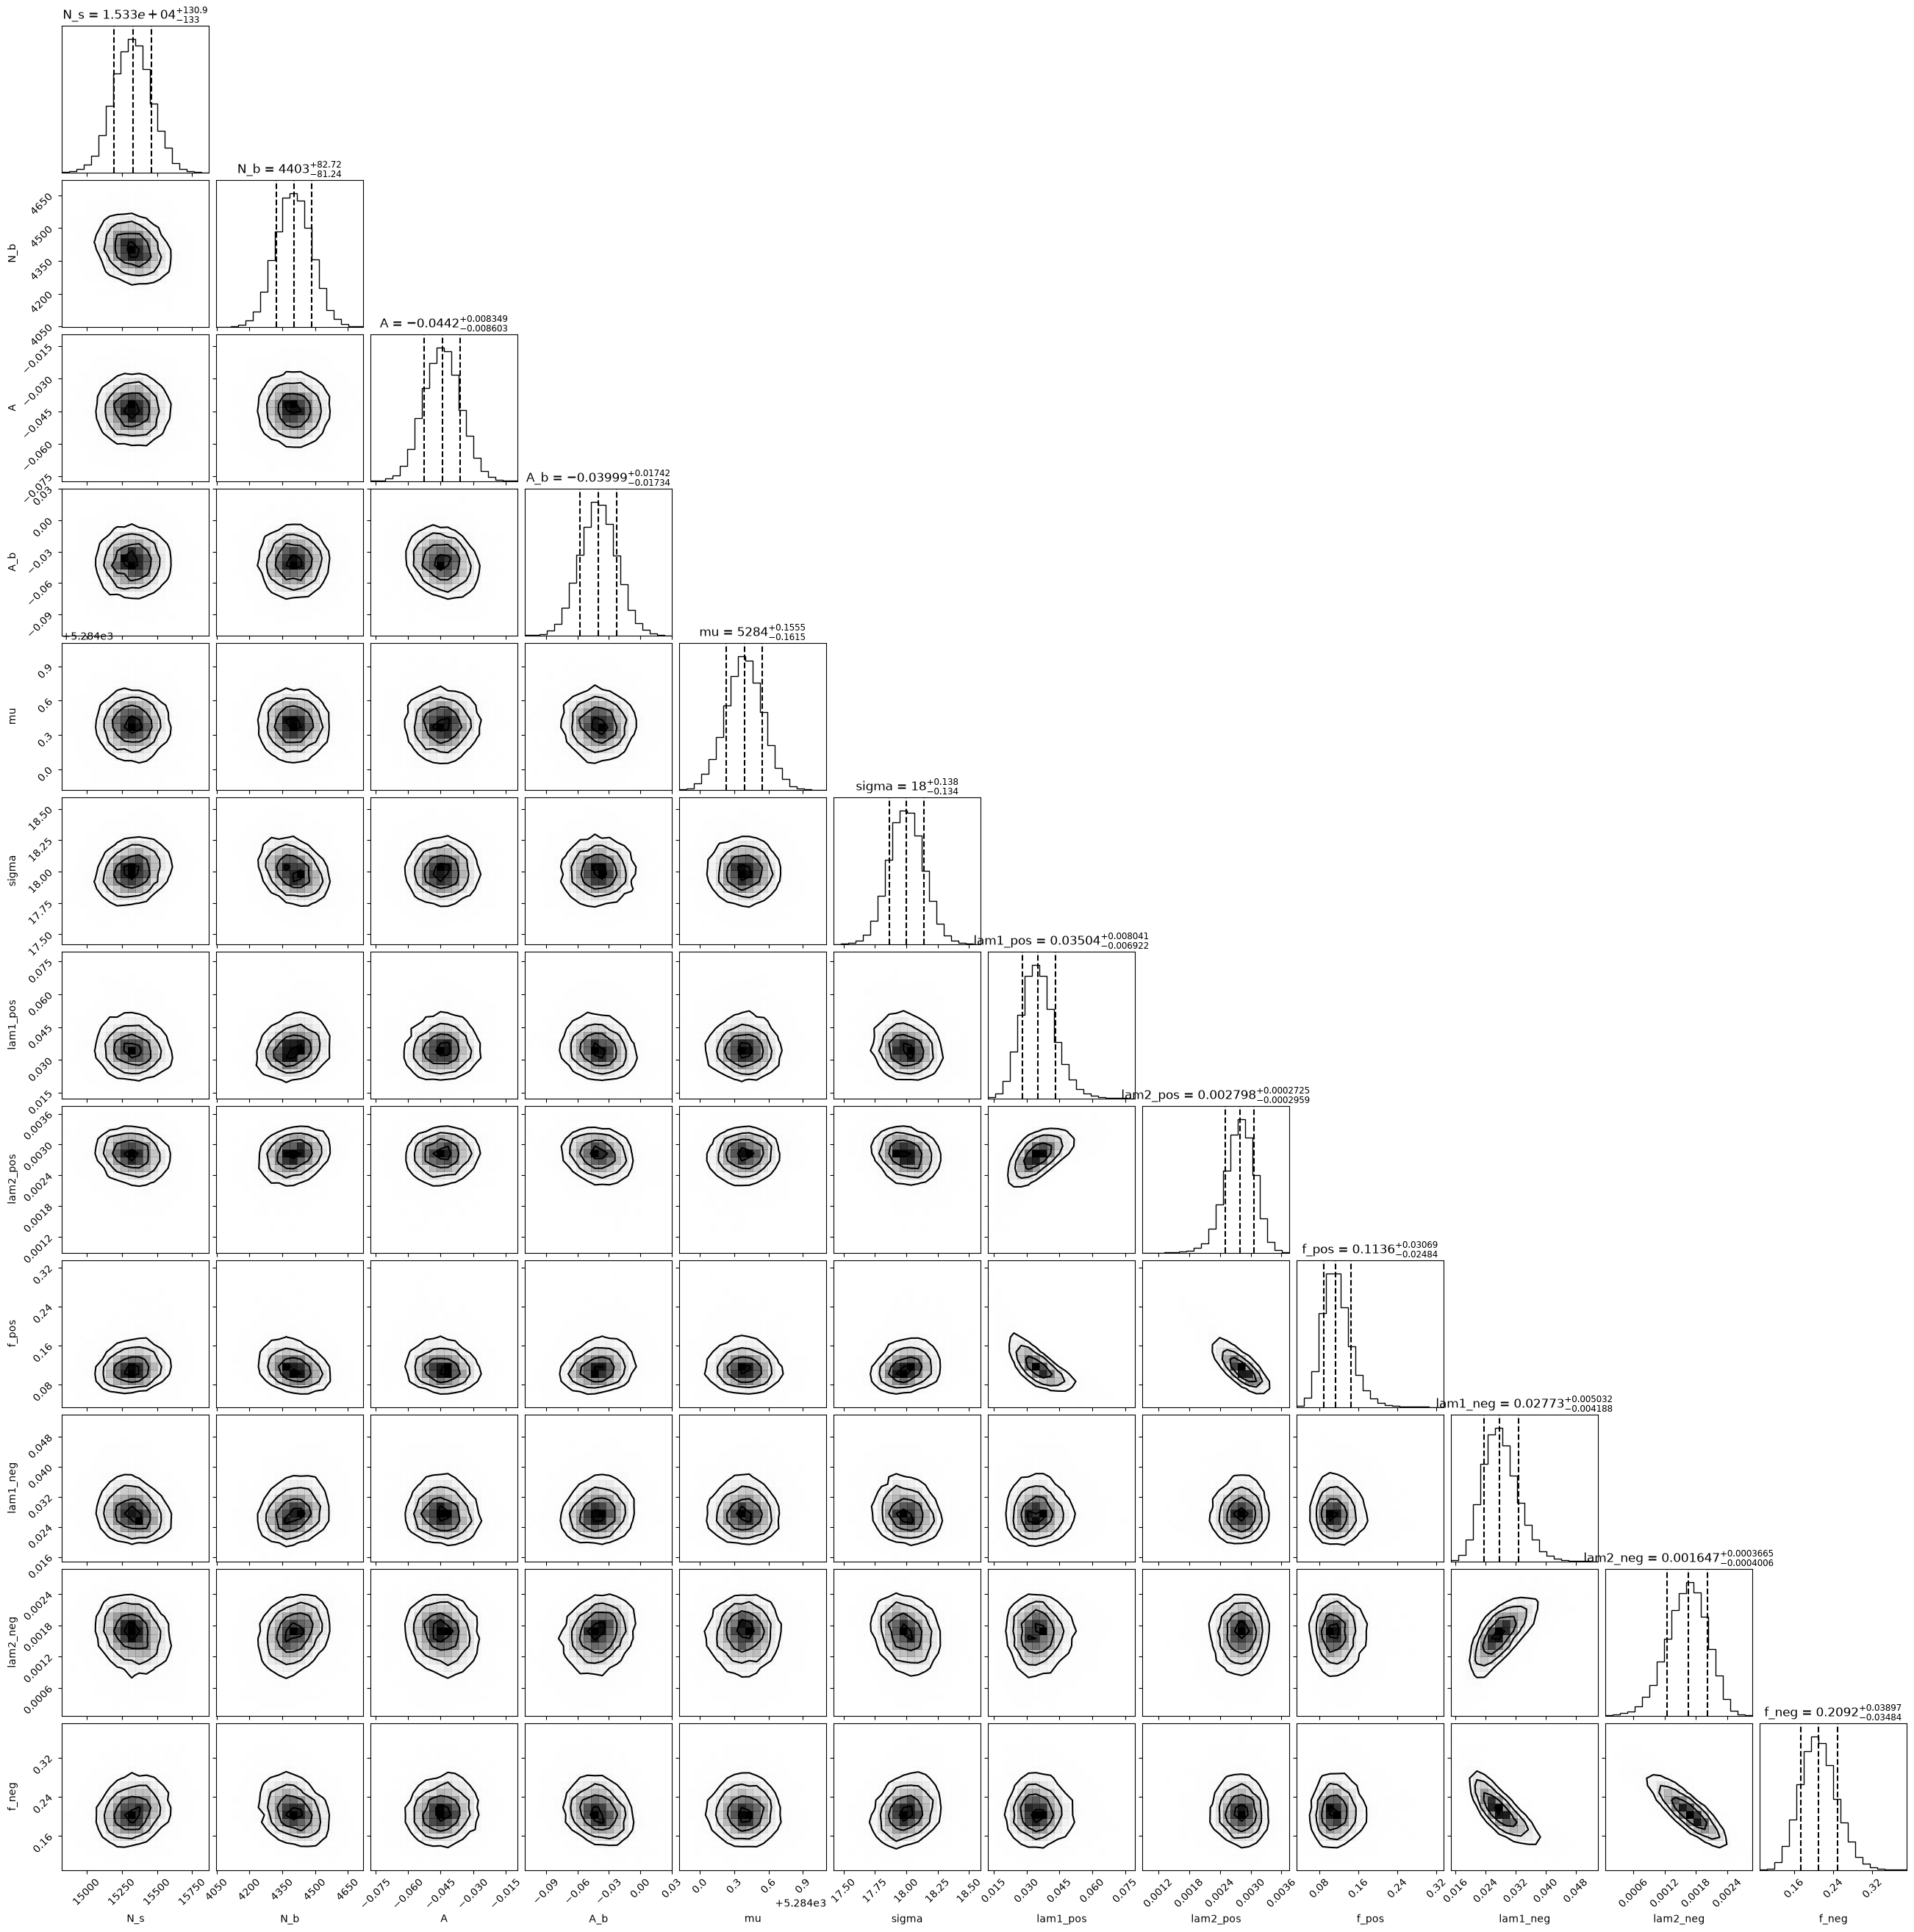

In [4]:
import corner
th = nominal["_thinned"]
fig = corner.corner(th, labels=nominal["names"], quantiles=[0.16, 0.5, 0.84], show_titles=True,
                    plot_datapoints=False, title_fmt=".4g")
plt.show()

## Bayes factor (Savage-Dickey, approssimazione gaussiana)

$A=0$ e $A_b=0$ contro parametro libero, prior uniforme su $(-1,1)$ (densità $1/2$), odds a priori uguali.

In [5]:
bf_A = bn.bayes_factor_gaussian(nominal, "A", 1 / bn.prior_volume_A(bn.NOMINAL))
bf_Ab = bn.bayes_factor_gaussian(nominal, "A_b", 0.5)
print(f"A = 0  : BF_01 = {bf_A:.2e}   BF_10 = {1/bf_A:.2e}   ({abs(A['mean'])/A['sd']:.1f} sd da zero)")
print(f"A_b = 0: BF_01 = {bf_Ab:.2f}   BF_10 = {1/bf_Ab:.2f}   ({abs(nominal['A_b']['mean'])/nominal['A_b']['sd']:.1f} sd da zero)")

A = 0  : BF_01 = 1.14e-04   BF_10 = 8.81e+03   (5.2 sd da zero)
A_b = 0: BF_01 = 3.45   BF_10 = 0.29   (2.3 sd da zero)


## Controlli e studio sistematico (in parallelo)

Un unico lotto di fit indipendenti, ciascuno con la stessa lunghezza di catena del nominale:
- due fit con i walker distribuiti uniformemente su tutto il box del prior (Week 4: più catene da punti diversi);
- i due campioni di polarità del magnete (controllo incrociato, non sistematica);
- le varianti dello studio sistematico (`bn.VARIATIONS`, stessa lista dell'analisi frequentista) e il controllo del prior (`bn.PRIOR_CHECKS`);
- i due veti sul charm (`bn.CHARM_VETOES`), solo informativi.

In [6]:
fit_tasks = []
for s in (1, 2):
    fit_tasks.append((replace(bn.NOMINAL, name=f"dispersed_{s}"), data_nom.m.to_numpy(), data_nom.q.to_numpy(), NSTEPS, s, True))
for pol in ("down", "up"):
    d = data_nom[data_nom.magnet == pol]
    fit_tasks.append((replace(bn.NOMINAL, name=f"magnet_{pol}"), d.m.to_numpy(), d.q.to_numpy(), NSTEPS, 42, False,
                      os.path.join(RESULTS_DIR, f"magnet_{pol}_A_thinned.npy")))
for cfg in bn.VARIATIONS + bn.PRIOR_CHECKS + bn.CHARM_VETOES:
    d = bn.select(cands, cfg)
    fit_tasks.append((cfg, d.m.to_numpy(), d.q.to_numpy(), NSTEPS, 42, False))

fits = bn.run_parallel(fit_tasks, bn._fit_task, os.path.join(RESULTS_DIR, "fits.jsonl"),
                       key=lambda r: r["config"]["name"], n_workers=N_WORKERS)
fits = {r["config"]["name"]: r for r in fits}
for name, r in fits.items():
    print(f"{name:22s} n={r['n']:6d}  A={r['A']['median']:+.4f} [{r['A']['ci68'][0]:+.4f},{r['A']['ci68'][1]:+.4f}]  "
          f"dA={r['A']['median']-A['median']:+.4f}  chi2/ndof={r['gof']['chi2']:.0f}/{r['gof']['ndof']}  "
          f"chain/tau={r['chain_over_tau_min']:.0f}" + (f"  bulk dopo {r['steps_to_bulk']} step" if r.get('dispersed') else ""))

/Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/nominal/fits.jsonl: 0 already done, 20 to run


  1/20 done, 8.6 min elapsed, ~163.4 min left


  2/20 done, 11.3 min elapsed, ~101.6 min left


  3/20 done, 11.5 min elapsed, ~65.0 min left


  4/20 done, 15.7 min elapsed, ~62.9 min left


...

  17/20 done, 41.7 min elapsed, ~7.4 min left


  18/20 done, 44.0 min elapsed, ~4.9 min left


  19/20 done, 44.2 min elapsed, ~2.3 min left


  20/20 done, 44.4 min elapsed, ~0.0 min left


dispersed_1            n= 19731  A=-0.0446 [-0.0529,-0.0360]  dA=-0.0003  chi2/ndof=164/88  chain/tau=72  bulk dopo 1158 step
dispersed_2            n= 19731  A=-0.0442 [-0.0528,-0.0356]  dA=+0.0001  chi2/ndof=164/88  chain/tau=68  bulk dopo 2588 step
magnet_down            n= 11636  A=-0.0497 [-0.0607,-0.0386]  dA=-0.0054  chi2/ndof=153/88  chain/tau=81
magnet_up              n=  8095  A=-0.0378 [-0.0507,-0.0251]  dA=+0.0065  chi2/ndof=150/88  chain/tau=77
window_lo5050          n= 21164  A=-0.0446 [-0.0531,-0.0362]  dA=-0.0003  chi2/ndof=217/98  chain/tau=51
window_lo5150          n= 18566  A=-0.0444 [-0.0528,-0.0359]  dA=-0.0001  chi2/ndof=142/78  chain/tau=10
window_hi5450          n= 19004  A=-0.0440 [-0.0524,-0.0357]  dA=+0.0002  chi2/ndof=137/58  chain/tau=103
window_hi5700          n= 20191  A=-0.0456 [-0.0540,-0.0373]  dA=-0.0014  chi2/ndof=200/108  chain/tau=81
bkg_single_exp         n= 19731  A=-0.0480 [-0.0564,-0.0395]  dA=-0.0037  chi2/ndof=298/92  chain/tau=210
bkg_shared

In [7]:
syst = bn.systematics(nominal, [fits[c.name] for c in bn.VARIATIONS])
for k, v in syst["variations"].items():
    sb = "-" if v["sigma_barlow"] is None else f"{v['sigma_barlow']:.4f}"
    print(f"{k:22s} shift={v['shift']:+.4f}  sigma_B={sb:>7s}  "
          f"{'ESCLUSA (dati)' if v['rejected_by_data'] else ('conta' if v['counts'] else 'non conta (Barlow)')}")
print("per gruppo :", {k: round(v, 4) for k, v in syst["groups"].items()})
print(f"sistematica totale ({syst['rule']}): {syst['total']:.4f}   vs statistica {A['sd']:.4f}")
pc = fits["prior_A_narrow"]
print(f"controllo del prior (A in (-0.3, 0.3), fuori dalla sistematica): A = {pc['A']['median']:.4f} (shift {pc['A']['median'] - A['median']:+.4f})")

window_lo5050          shift=-0.0003  sigma_B= 0.0009  non conta (Barlow)
window_lo5150          shift=-0.0001  sigma_B= 0.0007  non conta (Barlow)
window_hi5450          shift=+0.0002  sigma_B= 0.0009  non conta (Barlow)
window_hi5700          shift=-0.0014  sigma_B= 0.0010  conta
bkg_single_exp         shift=-0.0037  sigma_B=      -  ESCLUSA (dati)
bkg_shared_shape       shift=-0.0037  sigma_B=      -  conta
bkg_symmetric          shift=-0.0028  sigma_B=      -  conta
signal_crystal_ball    shift=-0.0002  sigma_B=      -  conta
signal_per_charge      shift=-0.0000  sigma_B=      -  conta
presel_probk_0.4       shift=-0.0032  sigma_B= 0.0038  non conta (Barlow)
presel_probk_0.6       shift=+0.0058  sigma_B= 0.0048  conta
presel_probpi_0.4      shift=+0.0022  sigma_B= 0.0022  conta
presel_probpi_0.6      shift=-0.0004  sigma_B= 0.0020  non conta (Barlow)
per gruppo : {'window': 0.0014, 'background': 0.0037, 'signal': 0.0002, 'preselection': 0.0058}
sistematica totale (Barlow for sample

## Toy-MC (in parallelo)

Pseudo-dataset generati dal modello nominale con i parametri alla mediana a posteriori; ogni toy è rifittato con lo stesso modello. Coverage degli intervalli al 68%/95%, bias e dispersione delle stime. È un closure test: non verifica l'adeguatezza del modello ai dati.

In [8]:
theta_true = {k: nominal[k]["median"] for k in nominal["names"]}
toy_tasks = [(i, theta_true, bn.NOMINAL, NSTEPS_TOY, 1000 + i) for i in range(N_TOYS)]
toys = bn.run_parallel(toy_tasks, bn._toy_task, os.path.join(RESULTS_DIR, "toys.jsonl"),
                       key=lambda r: r["toy"], n_workers=N_WORKERS, log_every=10)
cov = bn.coverage_summary(toys, theta_true["A"], A["sd"])
print(json.dumps(cov, indent=1))

/Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/nominal/toys.jsonl: 0 already done, 200 to run


  10/200 done, 15.1 min elapsed, ~287.4 min left


  20/200 done, 23.4 min elapsed, ~210.9 min left


  30/200 done, 31.2 min elapsed, ~176.8 min left


  40/200 done, 39.2 min elapsed, ~156.7 min left


...

  170/200 done, 150.1 min elapsed, ~26.5 min left


  180/200 done, 158.7 min elapsed, ~17.6 min left


  190/200 done, 168.5 min elapsed, ~8.9 min left


  200/200 done, 174.3 min elapsed, ~0.0 min left


{
 "n_toys": 200,
 "coverage_68": 0.65,
 "coverage_95": 0.93,
 "coverage_68_err": 0.03298484500494128,
 "coverage_95_err": 0.015411035007422441,
 "bias": -0.00023816884331041843,
 "bias_err": 0.0006242096863910885,
 "sd_estimates": 0.008827658042589339,
 "posterior_sd_data": 0.008481356527370304,
 "chain_over_tau_min_worst": 21.5828922452869
}


## Asimmetria locale nel piano di Dalitz (binning fisso $8\times8$)

Stessa procedura del modello semplificato, sulla finestra nominale: significatività di ogni bin rispetto all'asimmetria globale e test di omogeneità; ripetuto nella finestra di segnale ($|m-\mu|<2\sigma$, con $\mu,\sigma$ del fit nominale) e con i veti sul charm.

In [9]:
from scipy.stats import chi2 as _chi2, binom
def dalitz_test(d, label, min_events=20):
    lo2, hi2 = (np.minimum(d.m12, d.m13) / 1e3) ** 2, (np.maximum(d.m12, d.m13) / 1e3) ** 2
    q = d.q.to_numpy(); ag = (np.sum(q < 0) - np.sum(q > 0)) / len(q)
    el, eh = np.linspace(0, 16, 9), np.linspace(0, 30, 9)
    npl, _, _ = np.histogram2d(lo2[q > 0], hi2[q > 0], [el, eh]); nmi, _, _ = np.histogram2d(lo2[q < 0], hi2[q < 0], [el, eh])
    n = npl + nmi; k = n >= min_events
    ai = (nmi - npl)[k] / n[k]; s = (ai - ag) / np.sqrt((1 - ai ** 2) / n[k])
    c2 = float(np.sum(s ** 2)); nd = int(k.sum() - 1); nsig = int(np.sum(np.abs(s) > 3))
    out = {"label": label, "n": int(len(q)), "A_glob": float(ag), "bins_populated": int(k.sum()), "bins_3sigma": nsig,
           "chi2": c2, "ndof": nd, "p": float(_chi2.sf(c2, nd)),
           "p_at_least_nsig_if_uniform": float(binom.sf(nsig - 1, int(k.sum()), 2 * 0.00135)) if nsig else 1.0}
    print(f"{label:34s} n={out['n']:6d} A_glob={ag:+.4f}  {nsig}/{k.sum()} bin |S|>3  chi2={c2:.1f}/{nd}  p={out['p']:.1e}")
    return out

mu_n, sg_n = nominal["mu"]["median"], nominal["sigma"]["median"]
dalitz = [dalitz_test(data_nom, "finestra nominale"),
          dalitz_test(data_nom[np.abs(data_nom.m - mu_n) < 2 * sg_n], "finestra di segnale"),
          dalitz_test(bn.select(cands, bn.CHARM_VETOES[0]), "veto D0"),
          dalitz_test(bn.select(cands, bn.CHARM_VETOES[1]), "veto D0, J/psi, chi_c0")]

finestra nominale                  n= 19731 A_glob=-0.0432  2/32 bin |S|>3  chi2=80.8/31  p=2.6e-06
finestra di segnale                n= 15130 A_glob=-0.0461  3/29 bin |S|>3  chi2=95.6/28  p=2.6e-09
veto D0                            n= 18744 A_glob=-0.0464  2/32 bin |S|>3  chi2=79.2/31  p=4.2e-06
veto D0, J/psi, chi_c0             n= 16367 A_glob=-0.0426  1/32 bin |S|>3  chi2=74.4/31  p=2.0e-05


## Veti sul charm (controllo informativo)

$B^\pm\to D^0K^\pm$, $J/\psi K^\pm$, $\chi_{c0}K^\pm$ con la risonanza in $K^+K^-$ non sono charmless. Si scarta il candidato se almeno una delle due coppie $K^+K^-$ di carica opposta è entro la finestra (masse PDG; ±30 MeV per $D^0$ e $J/\psi$, ±60 MeV per $\chi_{c0}$, dalle larghezze dei picchi misurate nei dati). Stessa definizione dell'analisi frequentista; non entra nella sistematica. I fit sono nel lotto parallelo sopra.

In [10]:
for cv in bn.CHARM_VETOES:
    fv = fits[cv.name]
    print(f"{cv.name:20s} veto {cv.veto}: n={fv['n']}  A_raw = {fv['A']['median']:.4f}  "
          f"68% CI [{fv['A']['ci68'][0]:.4f}, {fv['A']['ci68'][1]:.4f}]  (spostamento {fv['A']['median'] - A['median']:+.4f})")

veto_D0              veto ('D0',): n=18744  A_raw = -0.0496  68% CI [-0.0584, -0.0409]  (spostamento -0.0053)
veto_D0_Jpsi_chic0   veto ('D0', 'Jpsi', 'chic0'): n=16367  A_raw = -0.0423  68% CI [-0.0516, -0.0329]  (spostamento +0.0020)


## Salvataggio

In [11]:
summary = {
    "model": asdict(bn.NOMINAL), "charm_halfwidth_MeV": bn.CHARM_HALFWIDTH, "smoke": SMOKE, "nsteps": NSTEPS, "nsteps_toy": NSTEPS_TOY,
    "n_candidates_window": len(data_nom),
    "nominal": bn.to_jsonable(nominal),
    "bayes_factor": {"A0_BF01": bf_A, "Ab0_BF01": bf_Ab},
    "checks": {k: fits[k] for k in ("dispersed_1", "dispersed_2", "magnet_down", "magnet_up", "prior_A_narrow")},
    "variations": {c.name: fits[c.name] for c in bn.VARIATIONS},
    "systematics": syst,
    "toys": cov,
    "dalitz": dalitz,
    "charm_vetoes": {cv.name: fits[cv.name] for cv in bn.CHARM_VETOES},
}
expected = ["nominal", "bayes_factor", "checks", "variations", "systematics", "toys", "dalitz", "charm_vetoes"]
assert all(summary.get(k) is not None for k in expected), "manca un risultato nel riepilogo"
save_json("nominal_summary.json", summary)

[saved] /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/nominal/nominal_summary.json
